# Bloque C - C4: Características cromáticas por célula

**Objetivo:** calcular, para cada célula, un conjunto de **características de color** que describan si tiene un parásito, y elegir las más útiles para el clasificador (C5).

**De dónde salen:**
- **C1:** el parásito es oscuro (G, L bajos) y violeta (b bajo, a y S altos). El color *promedio* de la célula separa poco; los **píxeles extremos** (percentiles 5 y 95) separan mejor.
- **C2:** conviene **normalizar por fondo** (balance de blancos), y evaluar **por paciente**, porque juntar pacientes infla los resultados.
- **C3:** la **máscara de manchas oscuras** dentro de la célula detecta parasitadas mucho mejor que cualquier estadístico de la célula entera.

**Cómo lo hacemos:**
1. Recortes de cada célula del GT con la función compartida `celulas_desde_gt`. Usamos el mismo `cell_id` que el Bloque B, para poder unir color y textura.
2. Normalizamos cada recorte por fondo (con la referencia de train de C2).
3. Calculamos las características **solo para train**. Test queda reservado para la evaluación final, donde se calcularán con estas mismas funciones y parámetros, sin reajustar nada.
4. El análisis para elegir características también se hace **solo con train**.
5. Guardamos todo en `results/features_color_gt.csv`.

In [1]:
# BLOQUE C - C4: Características cromáticas por célula

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from common.config import LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen
from common.generar_gt_utils import celulas_desde_gt
from segmentation.preprocess import mascara_circular

CARPETA_RESULTADOS = Path("results")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

COLOR_CLASE = {LABEL_UNINFECTED: "#eb6834", LABEL_PARASITIZED: "#1baf7a"}  # mismos colores que C1

## 1. Normalización por fondo y máscara de C3

Copiamos las funciones de C2 (normalización por fondo) y C3 (máscara de manchas oscuras) con los **parámetros elegidos en C3**:

| Parámetro | Valor |
|---|---|
| canal | G, relativo a la mediana de la célula |
| umbral | 39 niveles por debajo de la mediana |
| erosión del borde | 5 píxeles |
| área mínima de mancha | 50 píxeles |

La normalización por fondo multiplica cada píxel por un factor fijo por imagen, así que da lo mismo normalizar la imagen entera y recortar que **recortar y normalizar el recorte** con el factor de su imagen. Por eso podemos usar `celulas_desde_gt` directamente.

In [2]:
# Parámetros de la máscara elegidos en C3 (solo con train)
PARAMS_C3 = {"erosion": 5, "umbral": -39, "area_min": 50}


def mediana_fondo(imagen_rgb, campo):
    # Mediana R, G, B del fondo, estimado sin GT con Otsu sobre G (igual que en C2)
    verde = imagen_rgb[:, :, 1]
    umbral, _ = cv2.threshold(verde[campo].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return np.median(imagen_rgb[campo & (verde > umbral)].astype(float), axis=0)


def normalizar_fondo(imagen_rgb, fondo_imagen, fondo_ref):
    return np.clip(imagen_rgb * (fondo_ref / fondo_imagen), 0, 255).astype(np.uint8)


def kernel_eliptico(radio):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radio + 1, 2 * radio + 1))


def manchas_c3(verde, mascara, erosion, umbral, area_min):
    # Máscara de C3: píxeles con G muy por debajo de la mediana de la célula, solo en manchas grandes.
    # Devuelve la máscara final y el área de cada mancha.
    dentro = cv2.erode(mascara, kernel_eliptico(erosion)) > 0 if erosion > 0 else mascara > 0
    if not dentro.any():
        return np.zeros_like(dentro), np.array([], dtype=int)
    relativo = verde.astype(np.int16) - int(np.median(verde[dentro]))
    marcados = ((relativo < umbral) & dentro).astype(np.uint8)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(marcados, connectivity=8)
    grandes = [k for k in range(1, n) if stats[k, cv2.CC_STAT_AREA] >= area_min]
    return np.isin(etiquetas, grandes), stats[grandes, cv2.CC_STAT_AREA]


# Fondo de cada imagen de train y referencia = promedio de train
fondos = {}
for reg in cargar_subset("train"):
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    fondos[reg["image_id"]] = mediana_fondo(img, mascara_circular(img))
fondo_ref = np.mean(list(fondos.values()), axis=0)
print("Fondo de referencia (R, G, B):", fondo_ref.round(1))

Fondo de referencia (R, G, B): [220.3 181.1 166.4]


## 2. Las características

Para cada célula calculamos tres grupos:

**a) Color de la célula entera** (mediana dentro de la célula): `G_mediana`, `L_mediana`, `a_mediana`, `b_mediana`, `S_mediana`. Describen el tono general; en C1 separaban poco, pero las dejamos como referencia.

**b) Píxeles extremos** (de C1): `G_p5`, `L_p5`, `b_p5` (los más oscuros/azules) y `a_p95`, `S_p95` (los más magenta/saturados). Más dos versiones **relativas a la mediana de la propia célula**, que compensan si la célula está teñida más fuerte o más débil:
- `G_rel_p1` = percentil 1 de G − mediana de G (qué tan oscuro es lo más oscuro, comparado con el resto de la célula).
- `b_rel_p1` = lo mismo para b (qué tan violeta).

**c) Manchas de la máscara C3:**
- `n_manchas`: cantidad de manchas.
- `area_mancha_max`: área de la mancha más grande (píxeles).
- `frac_manchas`: proporción de la célula cubierta por manchas.
- `contraste_G_mancha`: mediana de G de la célula − G medio de las manchas (qué tan oscuras son).
- `contraste_b_mancha`: lo mismo para b (qué tan violetas son).

Si la célula no tiene manchas, las de este grupo valen 0.

In [3]:
def caracteristicas_color(recorte_rgb, mascara):
    dentro = mascara > 0
    hsv = cv2.cvtColor(recorte_rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(recorte_rgb, cv2.COLOR_RGB2LAB)
    canales = {"G": recorte_rgb[:, :, 1], "L": lab[:, :, 0], "a": lab[:, :, 1], "b": lab[:, :, 2], "S": hsv[:, :, 1]}
    valores = {nombre: canal[dentro].astype(float) for nombre, canal in canales.items()}

    f = {"n_pixeles": int(dentro.sum())}

    # a) Color de la célula entera
    for nombre, v in valores.items():
        f[f"{nombre}_mediana"] = np.median(v)

    # b) Píxeles extremos (absolutos y relativos a la mediana de la célula)
    for nombre in ["G", "L", "b"]:
        f[f"{nombre}_p5"] = np.percentile(valores[nombre], 5)
    for nombre in ["a", "S"]:
        f[f"{nombre}_p95"] = np.percentile(valores[nombre], 95)
    for nombre in ["G", "b"]:
        f[f"{nombre}_rel_p1"] = np.percentile(valores[nombre], 1) - f[f"{nombre}_mediana"]

    # c) Manchas de la máscara C3
    manchas, areas = manchas_c3(canales["G"], mascara, **PARAMS_C3)
    f["n_manchas"] = len(areas)
    f["area_mancha_max"] = int(areas.max()) if len(areas) else 0
    f["frac_manchas"] = manchas.sum() / dentro.sum()
    if manchas.any():
        f["contraste_G_mancha"] = f["G_mediana"] - canales["G"][manchas].mean()
        f["contraste_b_mancha"] = f["b_mediana"] - canales["b"][manchas].mean()
    else:
        f["contraste_G_mancha"] = 0.0
        f["contraste_b_mancha"] = 0.0
    return f


filas = []
for meta, recorte, mascara in celulas_desde_gt("train"):
    recorte = normalizar_fondo(recorte, fondos[meta["image_id"]], fondo_ref)
    filas.append({**meta, **caracteristicas_color(recorte, mascara)})

features = pd.DataFrame(filas)
COLUMNAS_ID = ["cell_id", "image_id", "patient_id", "split", "label"]
CARACTERISTICAS = [c for c in features.columns if c not in COLUMNAS_ID + ["n_pixeles"]]

print("Células de train por clase:")
print(features["label"].value_counts())
print("\nCaracterísticas:", len(CARACTERISTICAS))

Células de train por clase:
label
Uninfected          2135
Parasitized          217
White_Blood_Cell      10
Name: count, dtype: int64

Características: 17


In [4]:
ruta_csv = CARPETA_RESULTADOS / "features_color_gt.csv"
features.to_csv(ruta_csv, index=False)
print("Guardado:", ruta_csv, features.shape)
features.head()

Guardado: results/features_color_gt.csv (2362, 23)


,cell_id,image_id,patient_id,split,label,n_pixeles,G_mediana,L_mediana,a_mediana,b_mediana,...,b_p5,a_p95,S_p95,G_rel_p1,b_rel_p1,n_manchas,area_mancha_max,frac_manchas,contraste_G_mancha,contraste_b_mancha
0,208C67P28N_ThinF_IMG_20150819_115417_1-1,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,14284,141.0,163.0,150.0,128.0,...,126.0,155.0,83.0,-78.00,-21.00,1,142,0.009941,95.605634,24.669014
1,208C67P28N_ThinF_IMG_20150819_115417_1-2,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,14943,145.0,167.0,150.0,133.0,...,127.0,158.0,92.0,-65.00,-22.00,1,137,0.009168,105.532847,30.883212
2,208C67P28N_ThinF_IMG_20150819_115417_1-3,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,16379,140.0,162.0,150.0,128.0,...,127.0,152.0,77.0,-35.22,-13.00,1,152,0.009280,97.447368,25.973684
3,208C67P28N_ThinF_IMG_20150819_115417_1-4,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,13242,145.0,166.0,148.0,131.0,...,128.0,153.0,78.0,-68.59,-17.59,1,139,0.010497,96.633094,21.928058
4,208C67P28N_ThinF_IMG_20150819_115417_1-5,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Uninfected,14799,154.0,174.0,147.0,136.0,...,133.0,149.0,70.0,-12.00,-3.00,0,0,0.000000,0.000000,0.000000


## 3. ¿Qué tan bien separa cada característica? (solo train)

Para cada característica medimos el **AUC** entre parasitadas y no parasitadas (sin glóbulos blancos), de dos formas:
- **AUC global:** juntando todas las células de train.
- **AUC por paciente (media):** calculado dentro de cada paciente y promediado. Como vimos en C2, el global puede estar inflado por diferencias entre pacientes; el por paciente mide si la característica separa **dentro de un mismo preparado**, que es lo que importa para un paciente nuevo.

Igual que en C1, usamos `max(AUC, 1 − AUC)` y anotamos el sentido.

In [5]:
train = features[features["label"] != LABEL_WBC].reset_index(drop=True)
y = (train["label"] == LABEL_PARASITIZED).values


def auc_con_sentido(es_positivo, valores):
    auc = roc_auc_score(es_positivo, valores)
    return max(auc, 1 - auc), ("mayor en parasitadas" if auc >= 0.5 else "menor en parasitadas")


filas_rank = []
for c in CARACTERISTICAS:
    auc_global, sentido = auc_con_sentido(y, train[c])
    # Por paciente: usamos el mismo sentido que el global, para que un AUC < 0.5 cuente como error
    signo = 1 if sentido == "mayor en parasitadas" else -1
    auc_pacientes = [
        roc_auc_score(y[train["patient_id"] == p], signo * train.loc[train["patient_id"] == p, c])
        for p in train["patient_id"].unique()
    ]
    filas_rank.append({
        "caracteristica": c,
        "AUC global": auc_global,
        "AUC por paciente (media)": np.mean(auc_pacientes),
        "AUC por paciente (peor)": np.min(auc_pacientes),
        "sentido": sentido,
    })

ranking = pd.DataFrame(filas_rank).sort_values("AUC por paciente (media)", ascending=False).reset_index(drop=True)
ranking.round(3)

,caracteristica,AUC global,AUC por paciente (media),AUC por paciente (peor),sentido
0,b_rel_p1,0.981,0.974,0.897,menor en parasitadas
1,contraste_G_mancha,0.988,0.961,0.785,mayor en parasitadas
2,contraste_b_mancha,0.986,0.961,0.786,mayor en parasitadas
3,G_rel_p1,0.987,0.959,0.791,menor en parasitadas
4,n_manchas,0.984,0.958,0.785,mayor en parasitadas
5,frac_manchas,0.982,0.958,0.786,mayor en parasitadas
6,area_mancha_max,0.982,0.957,0.786,mayor en parasitadas
7,a_p95,0.885,0.832,0.757,mayor en parasitadas
8,S_p95,0.869,0.804,0.738,mayor en parasitadas
9,G_p5,0.882,0.785,0.669,menor en parasitadas


## 4. Redundancia entre características

Muchas características miden casi lo mismo (por ejemplo `G_p5` y `L_p5`). Usar dos muy correlacionadas no agrega información al clasificador. Medimos la **correlación de Spearman** (por rangos, no supone relación lineal) entre todas, en train.

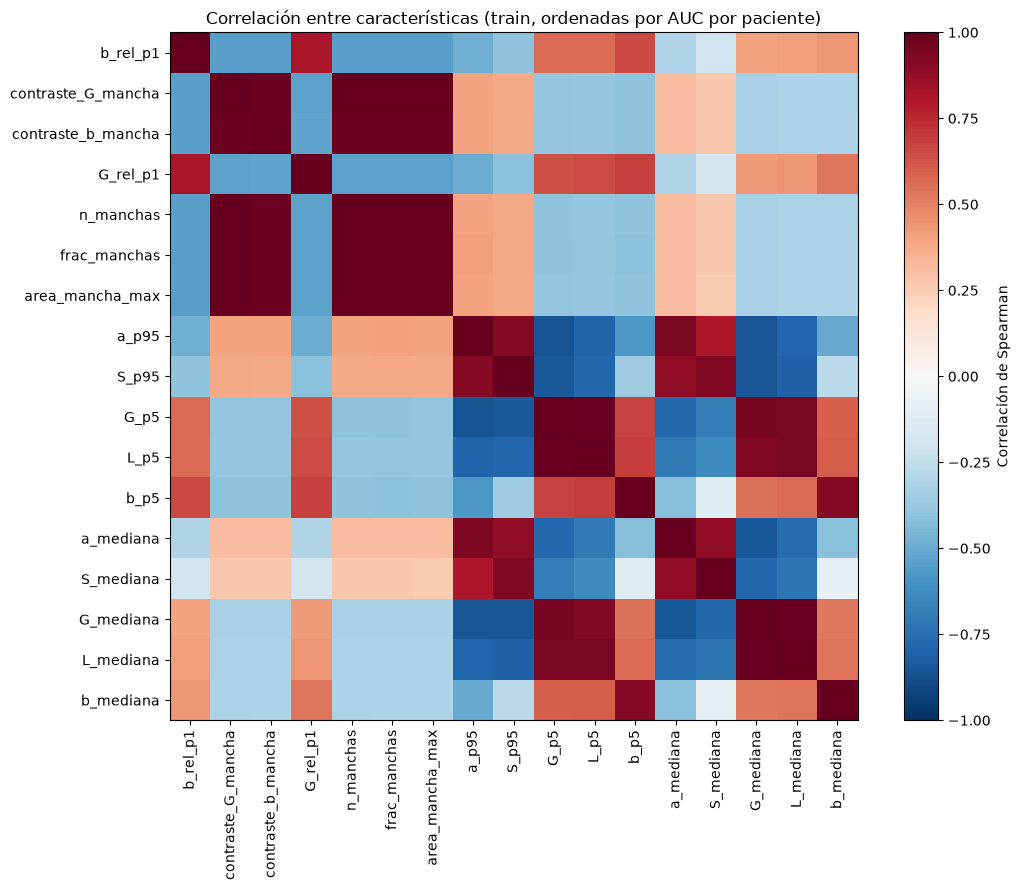

In [6]:
correlacion = train[ranking["caracteristica"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlacion)))
ax.set_xticklabels(correlacion.columns, rotation=90)
ax.set_yticks(range(len(correlacion)))
ax.set_yticklabels(correlacion.index)
fig.colorbar(im, ax=ax, fraction=0.046, label="Correlación de Spearman")
ax.set_title("Correlación entre características (train, ordenadas por AUC por paciente)")
plt.tight_layout()
plt.show()

## 5. Selección de características

Regla simple (selección "golosa"):
1. Recorremos las características de mejor a peor **AUC por paciente**.
2. Agregamos una si su AUC por paciente es al menos `AUC_MIN` y **no está muy correlacionada** (|ρ| < `RHO_MAX`) con ninguna ya elegida.

Así nos quedamos con pocas características, buenas y que aportan información distinta.

In [7]:
AUC_MIN = 0.8
RHO_MAX = 0.8

seleccionadas = []
for _, fila in ranking.iterrows():
    c = fila["caracteristica"]
    if fila["AUC por paciente (media)"] < AUC_MIN:
        continue
    if all(abs(correlacion.loc[c, s]) < RHO_MAX for s in seleccionadas):
        seleccionadas.append(c)

seleccion = ranking[ranking["caracteristica"].isin(seleccionadas)].copy()
seleccion["seleccionada"] = True
ranking_guardar = ranking.merge(seleccion[["caracteristica", "seleccionada"]], on="caracteristica", how="left")
ranking_guardar["seleccionada"] = ranking_guardar["seleccionada"].fillna(False).astype(bool)
ranking_guardar.to_csv(CARPETA_RESULTADOS / "c4_ranking_color.csv", index=False)

print("Seleccionadas:", seleccionadas)
correlacion.loc[seleccionadas, seleccionadas].round(2)

Seleccionadas: ['b_rel_p1', 'contraste_G_mancha', 'a_p95']


,b_rel_p1,contraste_G_mancha,a_p95
b_rel_p1,1.00,-0.54,-0.48
contraste_G_mancha,-0.54,1.00,0.40
a_p95,-0.48,0.40,1.00


Distribución de las características seleccionadas por clase (train). En el eje Y, la **frecuencia relativa**: cada clase suma 1, para que las parasitadas (que son ~10 veces menos) no queden aplastadas.

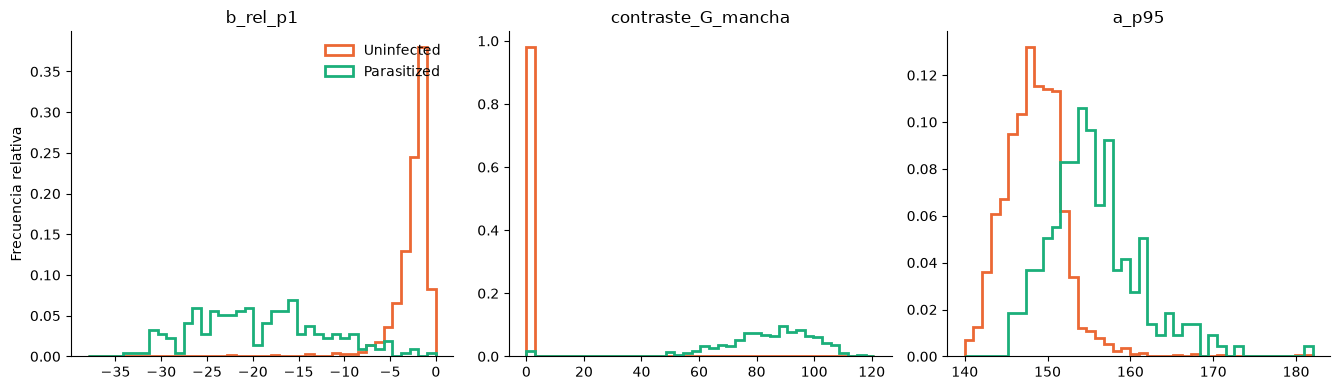

In [8]:
fig, ax = plt.subplots(1, len(seleccionadas), figsize=(4.5 * len(seleccionadas), 4), squeeze=False)
for eje, c in zip(ax[0], seleccionadas):
    bins = np.histogram_bin_edges(train[c], bins=40)
    for clase in [LABEL_UNINFECTED, LABEL_PARASITIZED]:
        valores = train.loc[train["label"] == clase, c]
        pesos = np.ones(len(valores)) / len(valores)  # frecuencia relativa: cada clase suma 1
        eje.hist(valores, bins=bins, weights=pesos, histtype="step", linewidth=2,
                 color=COLOR_CLASE[clase], label=clase)
    eje.set_title(c)
    eje.spines[["top", "right"]].set_visible(False)
ax[0, 0].set_ylabel("Frecuencia relativa")
ax[0, 0].legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

## 6. Conclusiones de C4

1. **Las mejores características son las "locales"**: las que miran la zona más oscura/violeta de la célula **comparada con el resto de la misma célula** (`b_rel_p1`, `G_rel_p1`) y las de las **manchas de C3**. Todas tienen AUC por paciente ≈0.96-0.97.
2. **Las de la célula entera separan mal** en un paciente nuevo: las medianas tienen AUC por paciente entre 0.61 y 0.76, y en el peor paciente algunas quedan por debajo de 0.5 (separan al revés). Los percentiles absolutos de C1 (`G_p5`, `b_p5`) quedan en el medio (≈0.76-0.79). Es lo mismo que vimos en C2: el color absoluto cambia de un paciente a otro; la diferencia **dentro** de la célula, no tanto.
3. **La mejor es `b_rel_p1`** (qué tan violeta es lo más violeta de la célula, respecto de su mediana): AUC por paciente 0.974 y 0.897 en el peor paciente, el más estable de todos. Además no depende de ningún umbral ajustado.
4. Las características de manchas de C3 (`n_manchas`, `area_mancha_max`, `frac_manchas`, contrastes) están **casi perfectamente correlacionadas** entre sí: en las sanas casi todas valen 0. Con una alcanza.
5. **Seleccionadas** (AUC por paciente ≥ 0.8 y |ρ| < 0.8 entre ellas): **`b_rel_p1`, `contraste_G_mancha` y `a_p95`**. Miden tres cosas distintas: lo violeta local, la mancha oscura de C3 y lo magenta de la célula.
6. **Ojo:** el umbral de la máscara C3 se eligió con estas mismas células de train, así que el AUC de las características de manchas está un poco inflado. `b_rel_p1` no tiene ese problema. La evaluación sin sesgo queda para la evaluación final en test.

**Archivos generados (en `color_stain/results/`):**
- `features_color_gt.csv`: las 17 características para las células del GT de **train** (incluidos glóbulos blancos), con el mismo `cell_id` que `features_texture_gt_provisorio.csv` del Bloque B, para poder unirlas en C5.
- `c4_ranking_color.csv`: el ranking de la sección 3 con la columna `seleccionada`.